In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/raw/PJME_hourly.csv")

df = pd.read_csv(DATA_PATH)
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df = df.dropna(subset=["Datetime", "PJME_MW"])
df = df.sort_values("Datetime").reset_index(drop=True)

print("EDA notebook ready!")
print("Dataset shape:", df.shape)
print("Date range:", df["Datetime"].min(), "to", df["Datetime"].max())

EDA notebook ready!
Dataset shape: (145366, 2)
Date range: 2002-01-01 01:00:00 to 2018-08-03 00:00:00


count    145366.000000
mean      32080.222831
std        6464.012166
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64

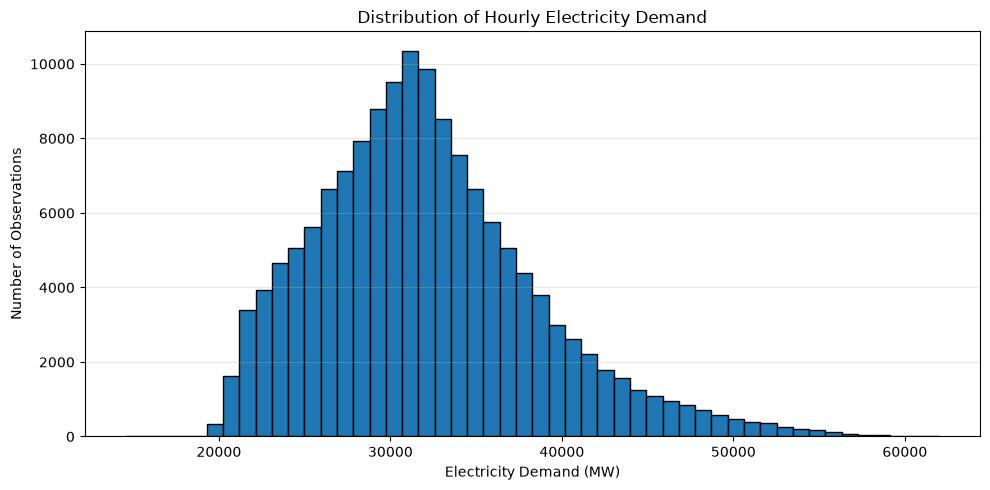

In [2]:

# Basic statistical summary
display(df["PJME_MW"].describe())

# Distribution of electricity demand
plt.figure(figsize=(10, 5))
plt.hist(df["PJME_MW"], bins=50, edgecolor="black")
plt.title("Distribution of Hourly Electricity Demand")
plt.xlabel("Electricity Demand (MW)")
plt.ylabel("Number of Observations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


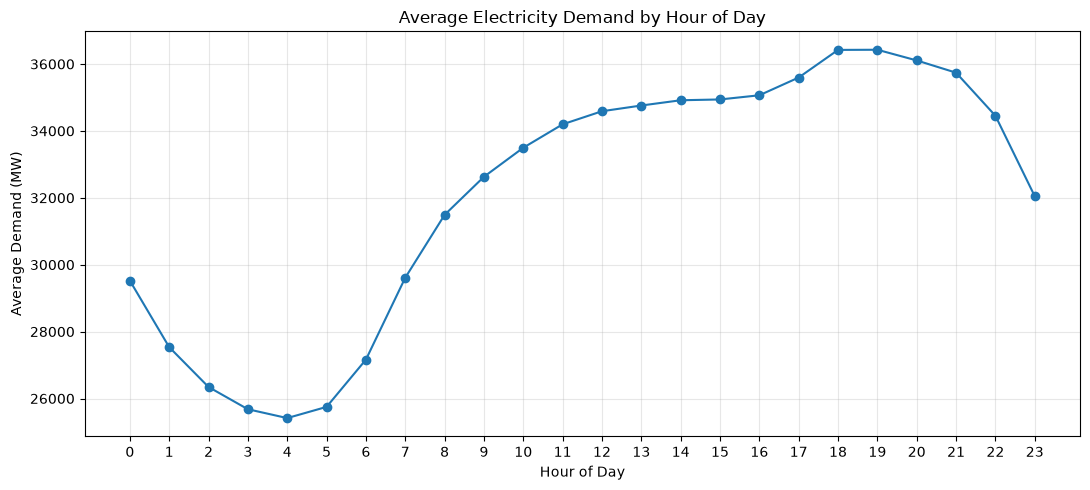

Lowest average demand hour: 4
Highest average demand hour: 19


In [3]:

df["Hour"] = df["Datetime"].dt.hour

hourly_avg = df.groupby("Hour")["PJME_MW"].mean()

plt.figure(figsize=(11, 5))
plt.plot(hourly_avg.index, hourly_avg.values, marker="o")
plt.title("Average Electricity Demand by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Lowest average demand hour:", hourly_avg.idxmin())
print("Highest average demand hour:", hourly_avg.idxmax())


DayType
Weekday    32996.092730
Weekend    29787.601494
Name: PJME_MW, dtype: float64

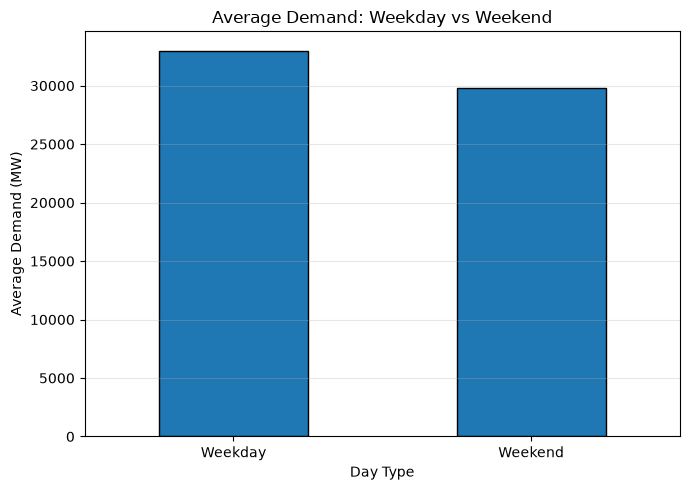

In [4]:

df["DayName"] = df["Datetime"].dt.day_name()
df["DayType"] = np.where(
    df["Datetime"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

daytype_avg = df.groupby("DayType")["PJME_MW"].mean()
display(daytype_avg)

plt.figure(figsize=(7, 5))
daytype_avg.reindex(["Weekday", "Weekend"]).plot(
    kind="bar",
    edgecolor="black"
)
plt.title("Average Demand: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Demand (MW)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


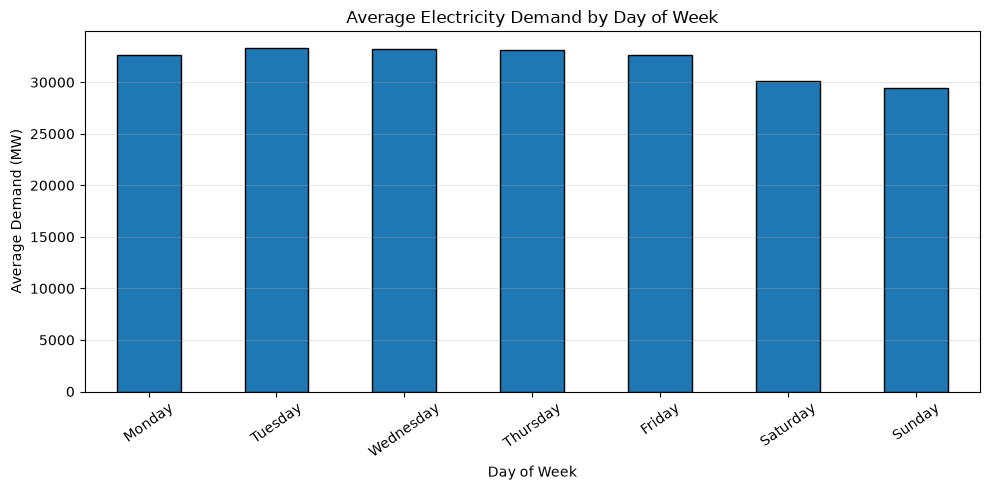

DayName
Tuesday      33272.265746
Wednesday    33261.497498
Thursday     33085.857727
Friday       32688.097688
Monday       32672.028420
Saturday     30162.880588
Sunday       29411.869930
Name: PJME_MW, dtype: float64

In [5]:

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_avg = (
    df.groupby("DayName")["PJME_MW"]
      .mean()
      .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))
weekday_avg.plot(kind="bar", edgecolor="black")
plt.title("Average Electricity Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Demand (MW)")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(weekday_avg.sort_values(ascending=False))


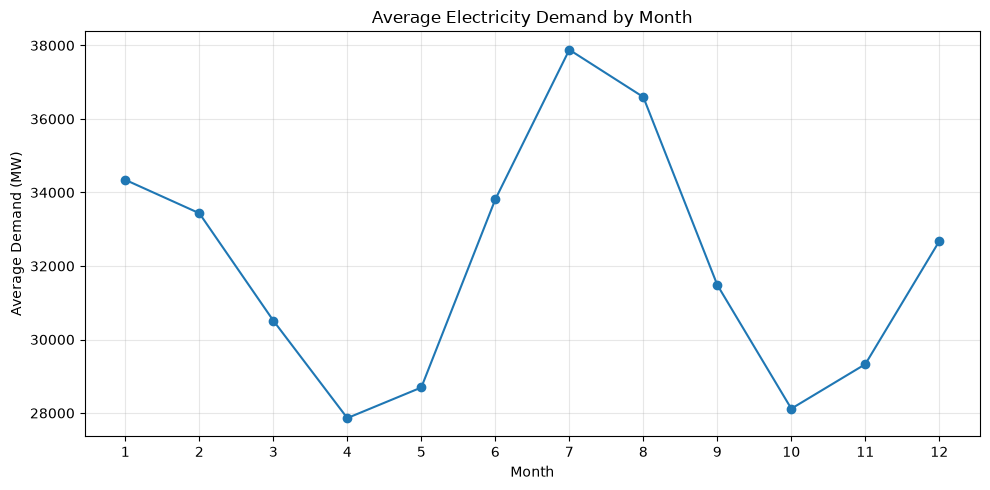

Month
1     34343.246462
2     33434.972049
3     30514.903609
4     27863.339354
5     28695.362113
6     33811.799183
7     37881.972881
8     36595.959675
9     31484.054688
10    28119.228675
11    29328.733872
12    32676.247669
Name: PJME_MW, dtype: float64

In [6]:

# Extract month and year
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month

# Average demand for each month across all years
monthly_avg = df.groupby("Month")["PJME_MW"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.title("Average Electricity Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_avg)


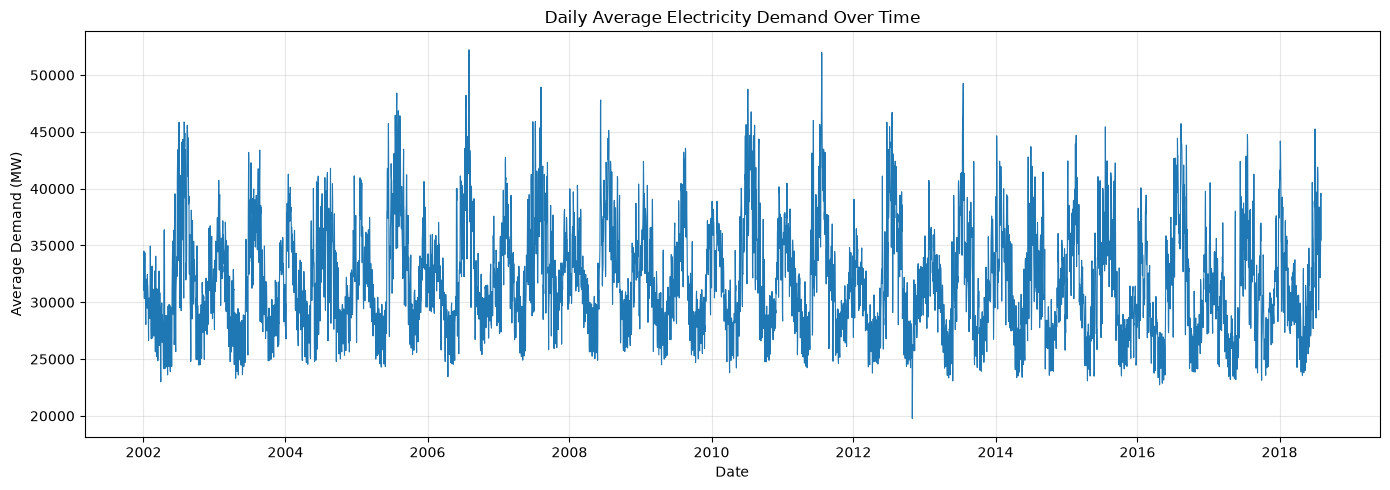

In [7]:

daily_avg = (
    df.set_index("Datetime")["PJME_MW"]
      .resample("D")
      .mean()
      .dropna()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_avg.index, daily_avg.values, linewidth=0.8)
plt.title("Daily Average Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Average Demand (MW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
